# Лаб №1 - Улучшение изображения

---

#### Импорт библиотек

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from rich.console import Console
from rich.table import Table
from rich.box import SIMPLE_HEAD

# отображение графиков в ноутбуке
%matplotlib inline

#### Загрузка изображения и вывод параметров

In [44]:
def load_and_inspect_image(file_path, var_name="img"):
    """Загружает изображение и выводит таблицу его параметров.

    Функция автоматизирует считывание файла через OpenCV, выполняет проверку 
    на корректность пути и генерирует минималистичную CLI-таблицу метаданных 
    на прозрачном фоне с помощью библиотеки Rich.

    Args:
        file_path (str): Относительный или абсолютный путь к файлу изображения.
        var_name (str, default "img"): Имя переменной, под которым изображение 
            будет отображаться в таблице.

    Returns:
        numpy.ndarray: Считанная матрица изображения в формате uint8 (Grayscale).

    Raises:
        FileNotFoundError: Если файл не найден или поврежден.
    """
    # 1. Загрузка изображения
    loaded_img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)

    # 2. Строгая проверка на ошибки загрузки
    if loaded_img is None:
        raise FileNotFoundError(f"Не удалось загрузить файл по пути: {file_path}")

    # 3. Генерация и вывод стильной прозрачной таблицы параметров
    console = Console()
    table = Table(box=SIMPLE_HEAD, show_edge=False, header_style="bold bright_black")

    table.add_column("Property", justify="left")
    table.add_column("Value", justify="left", style="cyan")

    table.add_row("Variable", var_name)
    table.add_row("Resolution", f"{loaded_img.shape[1]} × {loaded_img.shape[0]} px")
    table.add_row("Memory Size", f"{loaded_img.nbytes / 1024:.1f} KB ({loaded_img.nbytes} bytes)")
    table.add_row("Data Class", f"{loaded_img.dtype}")

    console.print(table)

    # 4. Возвращаем матрицу
    return loaded_img


---

### Визуаизация

#### Функция визуализации изображения и гистограммы яркости

In [35]:
def plot_image_and_hist(
    image, 
    title_prefix="Исходное", 
    hist_color="#3a86ff"
):
    """
    Отрисовка изображения и его гистограммы яркости на прозрачном фоне.
    
    Выводит интерактивное двухпанельное окно (subplot): слева отображается 
    полутоновое изображение, справа — гистограмма распределения интенсивностей пикселей.
    Цветовая палитра адаптирована под темную тему интерфейса JupyterLab.

    Параметры (Аргументы):
    ---------------------
    image : numpy.ndarray
        Входное изображение в формате матрицы NumPy (обычно типа uint8).
        
    title_prefix : str, default "Исходное"
        Текстовый префикс для заголовка окна с изображением 
        (например: "Исходное", "Преобразованное", "Гамма-коррекция").
        
    hist_color : str, default "#3a86ff"
        HEX-код или строковое название цвета для закраски столбцов гистограммы 
        (например: "#3a86ff" — синий, "#9b5de5" — фиолетовый).

    Возвращает:
    ----------
    None
        Функция выполняет прямой вывод графика на экран (plt.show()) и ничего не возвращает.
    """
    # 1. Сбрасываем стили в дефолт
    plt.style.use('default')

    # 2. Создаем фигуру с прозрачным фоном под темную тему JupyterLab
    fig = plt.figure(
        figsize=(12, 5), 
        facecolor='none'
    ) 

    # Окно 1: Вывод самого изображения
    ax1 = plt.subplot(1, 2, 1)
    ax1.set_facecolor('none') 
    plt.imshow(image, cmap="gray")
    plt.title(
        f"{title_prefix} изображение", 
        color="white", 
        fontsize=12
    ) 
    plt.axis("off")

    # Окно 2: Вывод гистограммы яркости
    ax2 = plt.subplot(1, 2, 2)
    ax2.set_facecolor('#1e1e1e')

    # Строим гистограмму
    plt.hist(
        image.ravel(), 
        bins=256,
        range=[0, 256],
        color=hist_color,
        alpha=0.85
    )

    # Настройки подписей, шкал и сеток
    plt.title(
        "Гистограмма яркости", 
        color="white", 
        fontsize=12
    )
    plt.xlabel(
        "Яркость пикселей", 
        color="#cccccc"
    )
    plt.ylabel(
        "Количество", 
        color="#cccccc"
    )
    ax2.tick_params(
        colors="white", 
        labelsize=10
    )

    # Цвет рамок осей
    for spine in ax2.spines.values():
        spine.set_color("#444444")

    # Тонкая приглушенная сетка
    plt.grid(
        True, 
        color="#444444", 
        linestyle=":", 
        
        linewidth=0.6)

    plt.tight_layout()
    plt.show()


#### Визуализация исходного изображения и гистограммы яркости

## Градационные преобразования

**Градационное преобразование (яркостное преобразование, англ. *Intensity / Gray-level Transformation*)** — это базовая технологическая операция цифровой обработки изображений, представляющая собой поэлементное (попиксельное) отображение множества значений яркости исходного изображения в новое множество значений по заданной функциональной зависимости, при котором новое значение яркости каждого пикселя формируется исключительно на основе его текущего значения, без учета значений соседних пикселей.

Математически градационное преобразование описывается уравнением:
$$s = T(r)$$

где:
*   $r$ — значение яркости исходного пикселя;
*   $s$ — значение яркости обработанного пикселя;
*   $T$ — оператор (функция) преобразования, определенный на интервале возможных значений яркости (для 8-битных изображений $r, s \in [0, 255]$).

В зависимости от вида монотонной функции $T(r)$ выделяют три ключевых типа индустриальных преобразований:

1.  **Линейные (Gradation / Contrast Stretching):**
    Используются для расширения динамического диапазона (растяжения контрастности).
2.  **Логарифмические ($s = c \cdot \log(1 + r)$):**
    Применяются для нелинейного расширения темных участков шкалы серого за счет сжатия ярких тонов. Эффективны при визуализации спектров фурье-преобразований.
3.  **Степенные / Гамма-коррекция ($s = c \cdot r^\gamma$):**
    Служат для коррекции нелинейных искажений устройств ввода-вывода (мониторов, камер). При $\gamma < 1$ изображение осветляется, при $\gamma > 1$ — затемняется.

Градационные методы относятся к классу **точечных (поэлементных) преобразований**. Это означает, что новое значение яркости конкретного пикселя зависит исключительно от его собственного исходного состояния и не определяется контекстом или значениями пикселей в его пространственной окрестности.


### Линейное градационное преобразование изображения

#### Функция линейного градационного преобразования с насыщением 

In [30]:
def imadjust(
    src, 
    low_in=None, 
    high_in=None, 
    low_out=0.0, 
    high_out=1.0, 
    gamma=1.0
):
    """
    Линейное градационное преобразование изображения (Аналог imadjust в MATLAB).
    
    Выполняет масштабирование и контрастирование динамического диапазона яркости
    входного полутонового изображения, опционально применяя степенную гамма-коррекцию.

    Параметры (Аргументы):
    ---------------------
    src : numpy.ndarray
        Исходное полутоновое (Grayscale) изображение типа uint8 (значения 0..255).
        
    low_in : float, optional
        Нижняя граница диапазона входной яркости в интервале [0.0, 1.0].
        Пиксели с яркостью ниже low_in станут равны low_out.
        Если None, рассчитывается автоматически (1-й процентиль гистограммы).
        
    high_in : float, optional
        Верхняя граница диапазона входной яркости в интервале [0.0, 1.0].
        Пиксели с яркостью выше high_in станут равны high_out.
        Если None, рассчитывается автоматически (99-й процентиль гистограммы).
        
    low_out : float, default 0.0
        Нижняя граница целевого (выходного) диапазона яркости в интервале [0.0, 1.0].
        Задает новый уровень «абсолютно черного» цвета.
        
    high_out : float, default 1.0
        Верхняя граница целевого (выходного) диапазона яркости в интервале [0.0, 1.0].
        Задает новый уровень «абсолютно белого» цвета.
        
    gamma : float, default 1.0
        Коэффициент степенного преобразования (гамма-коррекция):
        - gamma = 1.0 : Линейное отображение (контрастность растягивается равномерно).
        - gamma < 1.0 : График функции выгибается вверх, изображение становится светлее.
        - gamma > 1.0 : График функции выгибается вниз, изображение становится темнее.

    Возвращает:
    ----------
    numpy.ndarray
        Результирующее контрастированное изображение типа uint8 (диапазон 0..255).
    """
    
    # Переводим в float32 [0, 1]
    img_f = src.astype(np.float32) / 255.0
    
    # Если пороги не заданы вручную, автоматически находим реальный минимум и максимум
    if low_in is None or high_in is None:
        low_in, high_in = np.percentile(img_f, [1, 99])
    
    # Нормализация диапазона
    img_norm = (np.clip(img_f, low_in, high_in) - low_in) / (high_in - low_in)
    
    # Применение Гаммы
    img_gamma = np.power(img_norm, gamma)
    
    # Масштабирование в целевой выходной диапазон
    out = img_gamma * (high_out - low_out) + low_out
    return (np.clip(out, 0.0, 1.0) * 255.0).astype(np.uint8)

#### Изображение биологических клеток

In [127]:
img = load_and_inspect_image(
    "data/at3_1m4_01.tif", 
    var_name="img"
)

 Property      Value                   
───────────────────────────────────────
 Variable      img                     
 Resolution    640 × 480 px            
 Memory Size   300.0 KB (307200 bytes) 
 Data Class    uint8                   

In [128]:
img_imadjust = imadjust(
    img, 
    gamma=0.9
)

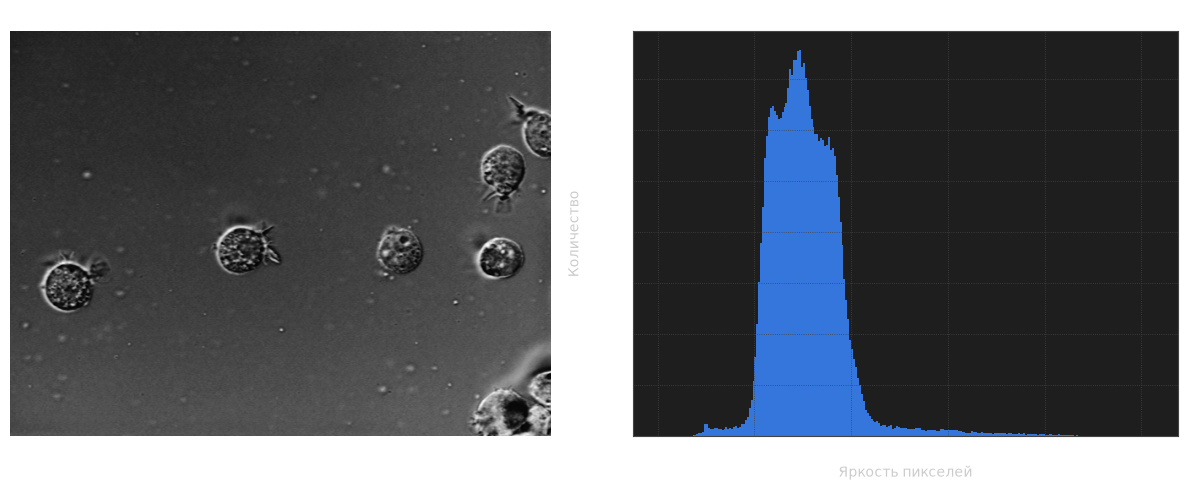

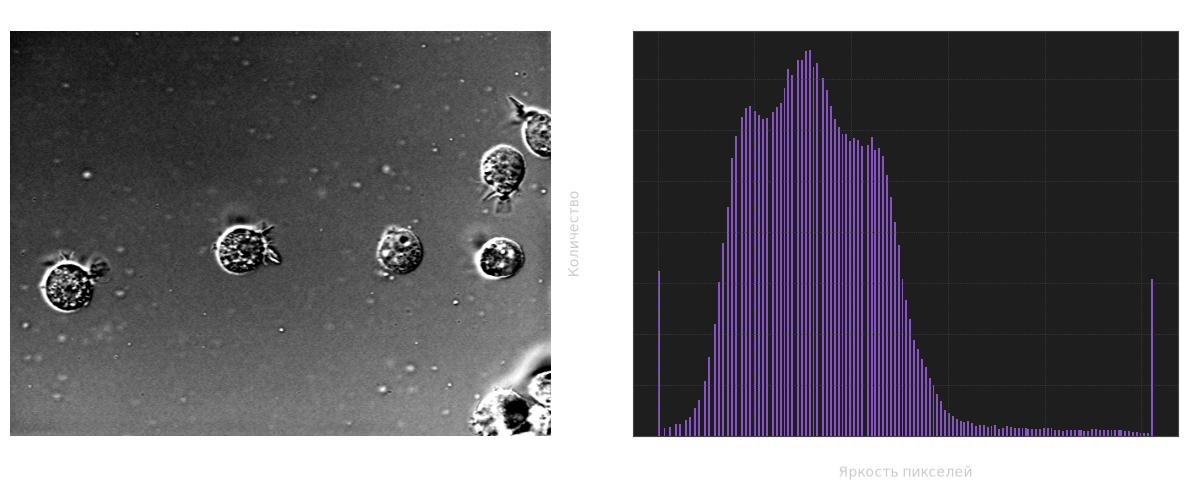

In [129]:
plot_image_and_hist(
    img,
    title_prefix="Исходное",
    hist_color="#3a86ff"
)

plot_image_and_hist(
    img_imadjust, 
    title_prefix="Результат imadjust (NumPy)", 
    hist_color="#9b5de5"
)

#### Изображение девочки

In [130]:
img = load_and_inspect_image(
    "data/pout.tif", 
    var_name="img"
)

 Property      Value                 
─────────────────────────────────────
 Variable      img                   
 Resolution    240 × 291 px          
 Memory Size   68.2 KB (69840 bytes) 
 Data Class    uint8                 

In [131]:
img_imadjust = imadjust(
    img, 
    gamma=0.9
)

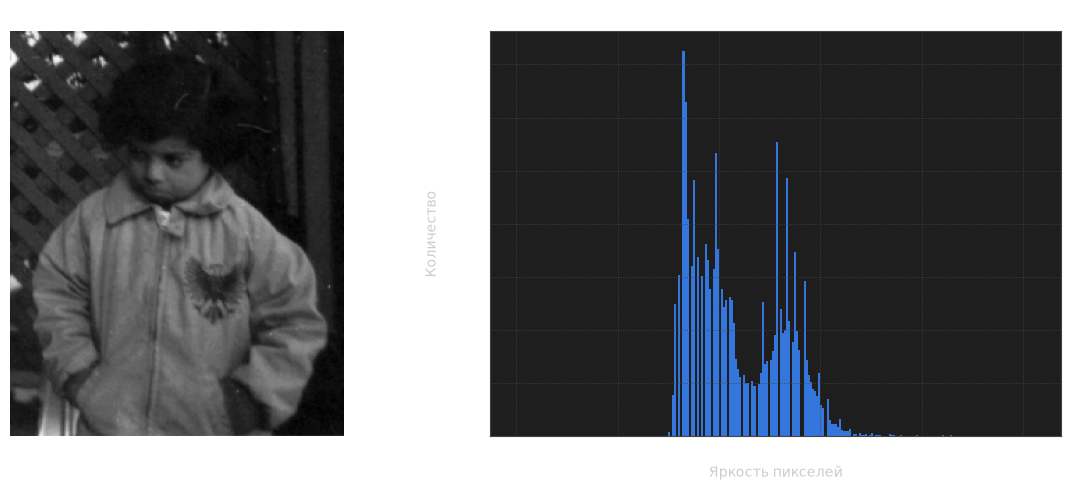

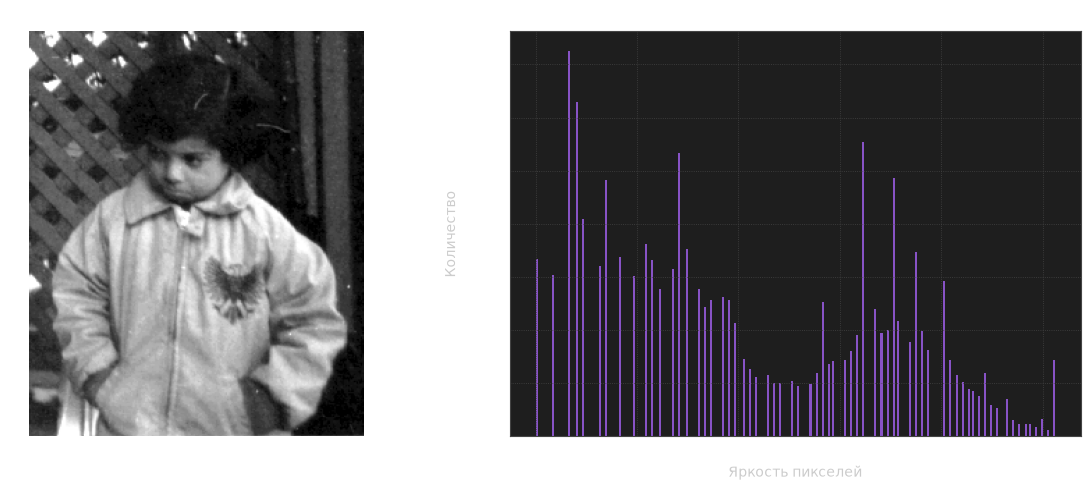

In [132]:
plot_image_and_hist(
    img,
    title_prefix="Исходное",
    hist_color="#3a86ff"
)

plot_image_and_hist(
    img_imadjust, 
    title_prefix="Результат imadjust (NumPy)", 
    hist_color="#9b5de5"
)

---

### Логарифмическое градационное преобразование изображения

#### Функция логарифмического преобразования

In [38]:
def log_transformation(src):
    """
    Выполняет логарифмическое градационное преобразование изображения.
    
    Математическая модель: s = c * ln(1 + r). Автоматически рассчитывает 
    коэффициент масштабирования 'c' для максимального расширения динамического 
    диапазона темных участков и предотвращения пересветов (засветов) кадра.

    Args:
        src (numpy.ndarray): Исходное полутоновое (Grayscale) изображение 
            типа uint8 (значения 0..255).

    Returns:
        numpy.ndarray: Преобразованное изображение типа uint8 (значения 0..255),
            адаптированное для визуализации скрытых деталей в темных зонах.
    """
    # Переводим в float32 в диапазон [0.0, 1.0] 
    img_f = src.astype(np.float32) / 255.0
    
    # Автоматический расчет константы c на основе максимального пикселя в изображении
    max_val = np.max(img_f)
    if max_val == 0:
        return src # Возвращаем исходную картинку, если она абсолютно черная
        
    c = 1.0 / np.log1p(max_val)
    
    # Применяем логарифм: s = c * ln(1 + r).
    img_log = c * np.log1p(img_f)
    
    # Возвращаем в стандартный формат uint8 (0..255)
    return (np.clip(img_log, 0.0, 1.0) * 255.0).astype(np.uint8)


#### Спектр Фурье

In [77]:
img = load_and_inspect_image(
    "data/pout.tif", 
    var_name="img"
)

f_transform = np.fft.fft2(img)
f_shift = np.fft.fftshift(f_transform) # Сдвигаем низкие частоты в центр
spectrum_raw = np.abs(f_shift)

img_log = log_transformation(spectrum_raw)

 Property      Value                 
─────────────────────────────────────
 Variable      img                   
 Resolution    240 × 291 px          
 Memory Size   68.2 KB (69840 bytes) 
 Data Class    uint8                 

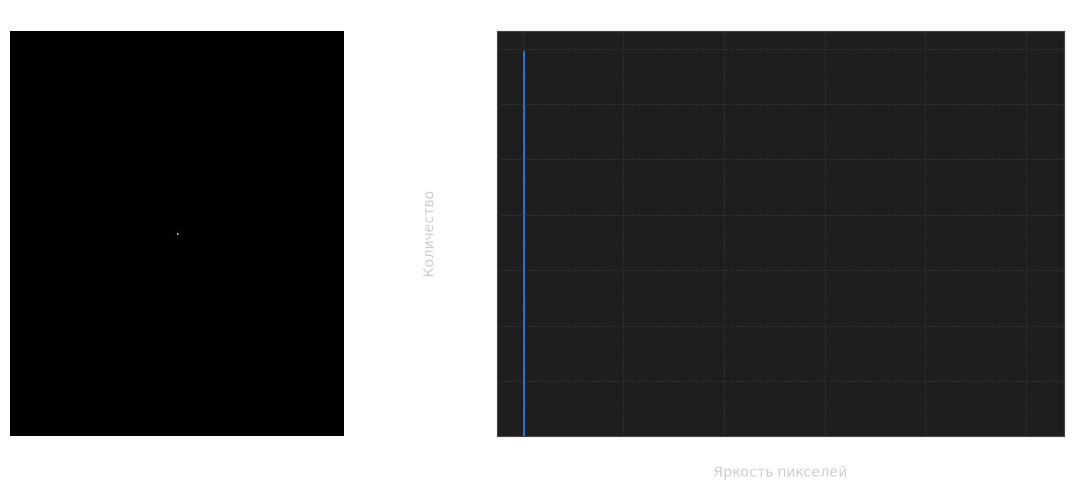

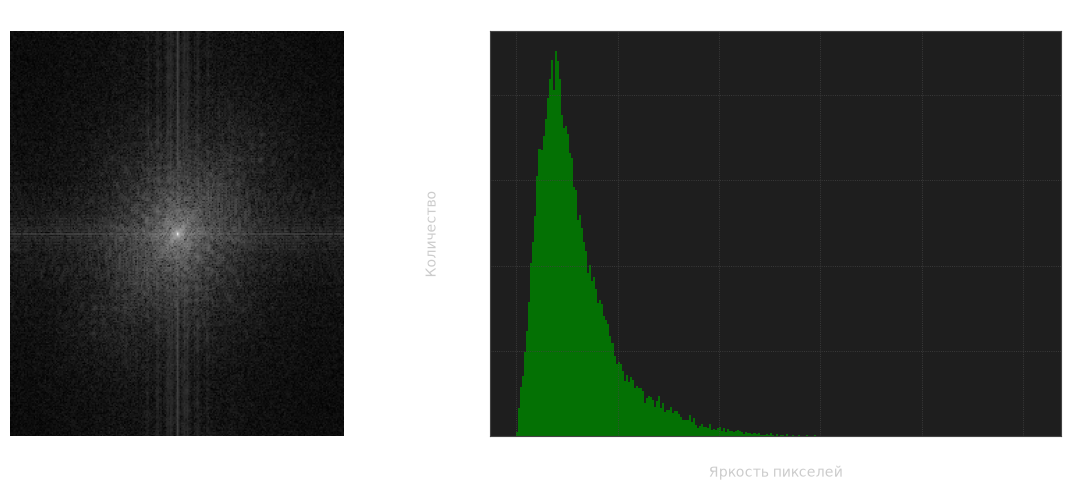

In [78]:
plot_image_and_hist(
    spectrum_linear,
    title_prefix="Исходное",
    hist_color="#3a86ff"
)

plot_image_and_hist(
    img_log,
    title_prefix="Логарифмическое", 
    hist_color="green"
)

#### Физический смысл спектра Фурье и его логарифмического преобразования

##### 1. Что такое спектр Фурье?
**Спектр Фурье** — это математическое представление цифрового изображения, переведенное из пространственного домена (координаты пикселей) в частотный домен. 
*   Он визуализирует не физические объекты, а **скорость и направление изменения яркости** на исходном кадре.
*   **Центр спектра (низкие частоты):** отвечает за глобальную освещенность, крупные однородные объекты и плавные градиенты.
*   **Периферия спектра (высокие частоты):** отвечает за резкие перепады яркости, четкие границы, контуры, мелкие текстуры и цифровой шум.

##### 2. Проблема визуализации сырых данных (Линейный масштаб)
В реальных изображениях энергия распределена экстремально неравномерно. Значение постоянной составляющей в самом центре (низкие частоты) может исчисляться **миллионами**, в то время как значения высоких частот на краях составляют всего **единицы или доли**. 

При попытке вывести сырой спектр на экран в стандартном линейном масштабе (`uint8`) динамический диапазон схлопывается: центральный пик полностью «ослепляет» систему, превращая спектр в **сплошной черный квадрат с единственной белой точкой в центре**.

##### 3. Роль логарифмического преобразования
Формула $s = c \cdot \ln(1 + r)$ выступает в роли **математического компрессора гигантского динамического диапазона**.

Логарифмическая функция обладает уникальным нелинейным свойством:
1.  **В области высоких значений (центр):** она жестко сжимает («приглушает») колоссальные пики яркости.
2.  **В области низких значений (периферия):** она агрессивно растягивает и усиливает мельчайшие, невидимые глазу различия в темных пикселях.

Логарифмическое преобразование адаптирует экстремальный математический разброс частот под физические возможности монитора, «проявляя» скрытые радиальные лучи, кольца и структуру текстур, которые в линейном виде были безвозвратно утеряны.


### Степенное градационное (гамма) преобразование изображения

#### Функция степенного градационного преобразования (гамма-коррекция)

In [85]:
def gamma_correction(
    src, 
    gamma=1.0, 
    c=1.0
):
    """Выполняет степенное градационное (гамма) преобразование изображения.
    
    Математическая модель: s = c * (r ^ gamma). Применяется для нелинейной 
    коррекции освещенности. При gamma < 1.0 изображение осветляется (вытягиваются тени), 
    при gamma > 1.0 — затемняется (приглушаются пересветы).

    Args:
        src (numpy.ndarray): Исходное полутоновое (Grayscale) изображение 
            типа uint8 (значения 0..255).
        gamma (float, default 1.0): Коэффициент нелинейности (степень).
        c (float, default 1.0): Масштабирующий коэффициент.

    Returns:
        numpy.ndarray: Преобразованное изображение типа uint8 (значения 0..255).
    """
    # Переводим в float32 в диапазон [0.0, 1.0]
    img_f = src.astype(np.float32) / 255.0
    
    # Применяем степенную функцию: s = c * (r ^ gamma)
    img_gamma = c * np.power(img_f, gamma)
    
    # Ограничиваем диапазон [0.0, 1.0] и возвращаем в формат uint8 (0..255)
    return (np.clip(img_gamma, 0.0, 1.0) * 255.0).astype(np.uint8)


#### Изображение фотографа - осветление (гамма меньше 1)

In [93]:
img = load_and_inspect_image(
    "data/cameraman.tif", 
    var_name="img"
)

img_gamma = gamma_correction(
    img,
    gamma=0.2
)

 Property      Value                 
─────────────────────────────────────
 Variable      img                   
 Resolution    256 × 256 px          
 Memory Size   64.0 KB (65536 bytes) 
 Data Class    uint8                 

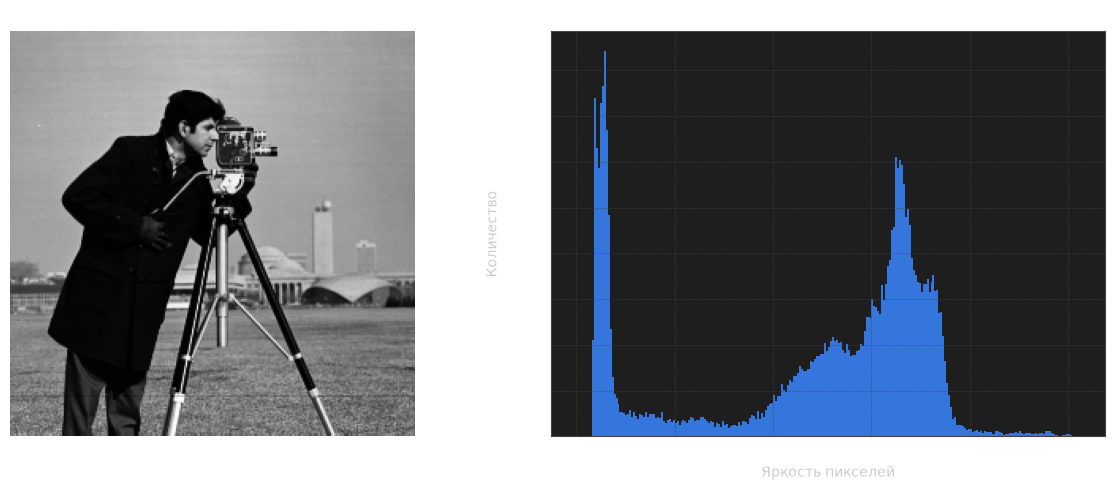

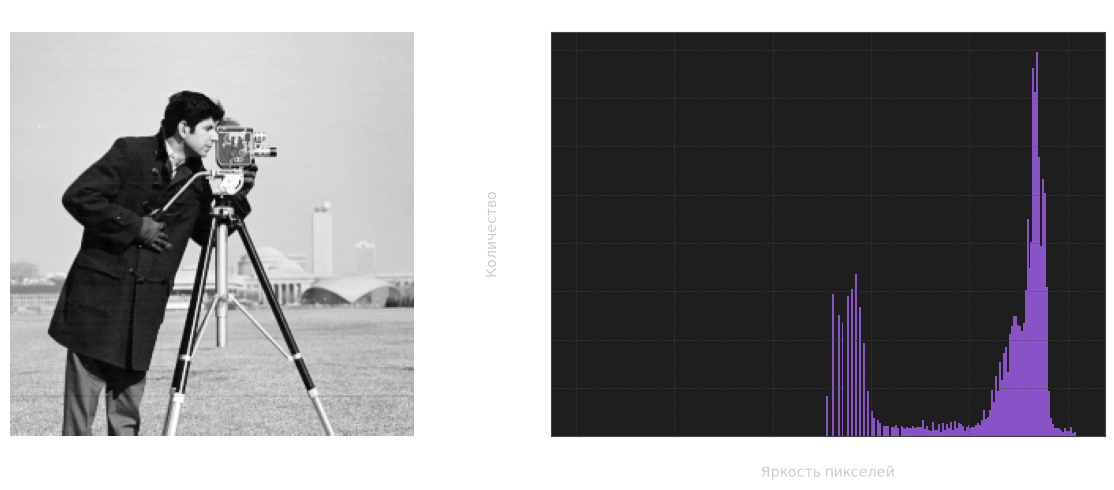

In [95]:
plot_image_and_hist(
    img,
    title_prefix="Исходное",
    hist_color="#3a86ff"
)

plot_image_and_hist(
    img_gamma, 
    title_prefix="Осветления гамма-коррекцией", 
    hist_color="#9b5de5"
)

#### Рентгеновский снимок позвоночника - затемнение (гамма больше 1)

In [115]:
img = load_and_inspect_image(
    "data/spine.tif", 
    var_name="img"
)

img_gamma_spine = gamma_correction(
    img,
    gamma=2.5
)

 Property      Value                   
───────────────────────────────────────
 Variable      img                     
 Resolution    490 × 367 px            
 Memory Size   175.6 KB (179830 bytes) 
 Data Class    uint8                   

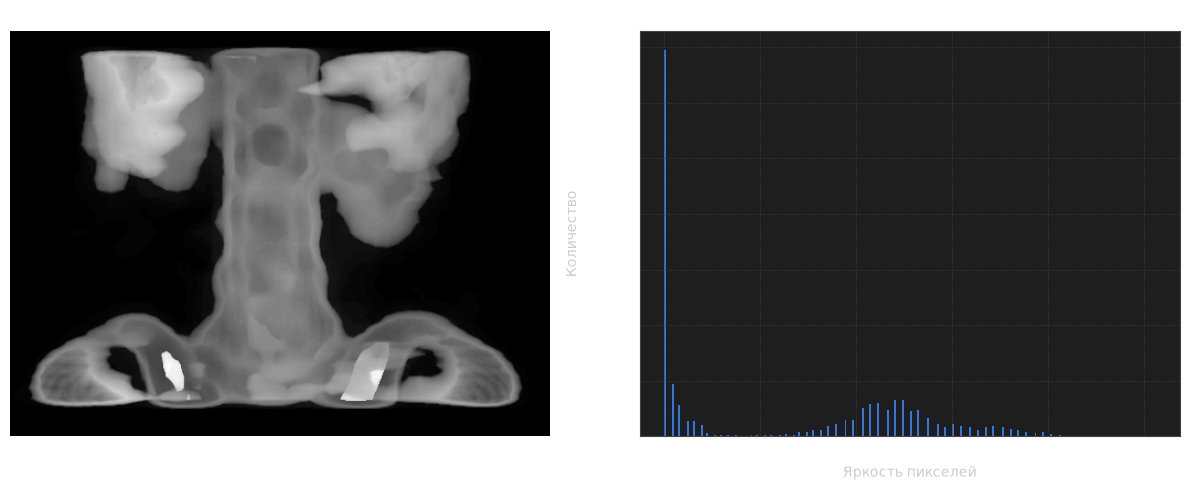

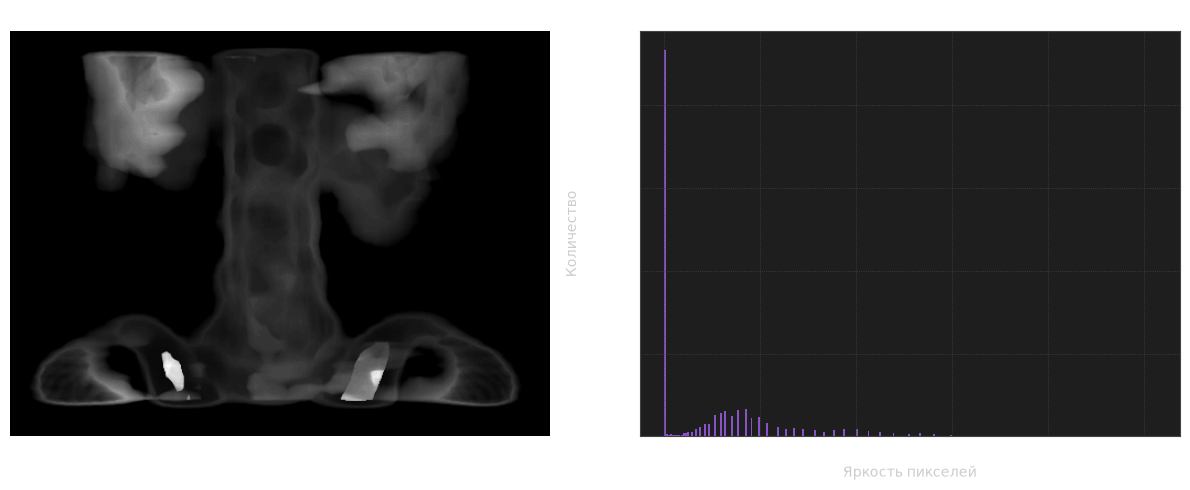

In [116]:
plot_image_and_hist(
    img,
    title_prefix="Исходное",
    hist_color="#3a86ff"
)

plot_image_and_hist(
    img_gamma_spine, 
    title_prefix="Затеменние гамма-коррекцией", 
    hist_color="#9b5de5"
)

### елинейное растяжение контрастности с помощью сигмоидальной функции

#### Функция преобразования растяжения контрастности яркости

In [102]:
def contrast_stretching_sigmoid(
    src, 
    m=None, 
    E=4.0
):
    """Выполняет нелинейное растяжение контрастности по сигмоидальной функции.
    
    Математическая модель: g = 1 / (1 + (m / I)^E). 
    Метод повышает глобальный контраст за счет S-образного перераспределения яркостей:
    темные тона смещаются ближе к абсолютно черному, светлые — к белому.

    Args:
        src (numpy.ndarray): Исходное полутоновое (Grayscale) изображение 
            типа uint8 (значения 0..255).
        m (float, optional): Точка перегиба (центр функции) в интервале (0.0, 1.0).
            Если None, автоматически рассчитывается как медиана яркости изображения,
            что гарантирует стабильный результат для любого кадра.
        E (float, default 4.0): Коэффициент крутизны (наклона) функции. 
            Чем выше E, тем выше контраст и тем ближе функция к пороговому бинарному разделению.

    Returns:
        numpy.ndarray: Преобразованное высококонтрастное изображение типа uint8 (0..255).
    """
    # Переводим в float32 в диапазон [0.0, 1.0]
    img_f = src.astype(np.float32) / 255.0
    
    # Если m не задан, берем медиану. 
    if m is None:
        m = np.median(img_f)
        # Защита от абсолютно черных изображений
        if m == 0: m = 0.5 
        
    # Предотвращаем деление на ноль, заменяя абсолютные нули на минимальное float-число
    eps = 1e-6
    img_safe = np.where(img_f == 0, eps, img_f)
    
    # Применяем формулу сигмоиды: g = 1 / (1 + (m / I)^E)
    img_contrast = 1.0 / (1.0 + np.power(m / img_safe, E))
    
    # Возвращаем результат в стандартном uint8 (0..255)
    return (np.clip(img_contrast, 0.0, 1.0) * 255.0).astype(np.uint8)

#### Изображение девочки

In [108]:
img = load_and_inspect_image(
    "data/pout.tif", 
    var_name="img"
)

img_contrast = contrast_stretching_sigmoid(
    img, 
    E=4.5
)

 Property      Value                 
─────────────────────────────────────
 Variable      img                   
 Resolution    240 × 291 px          
 Memory Size   68.2 KB (69840 bytes) 
 Data Class    uint8                 

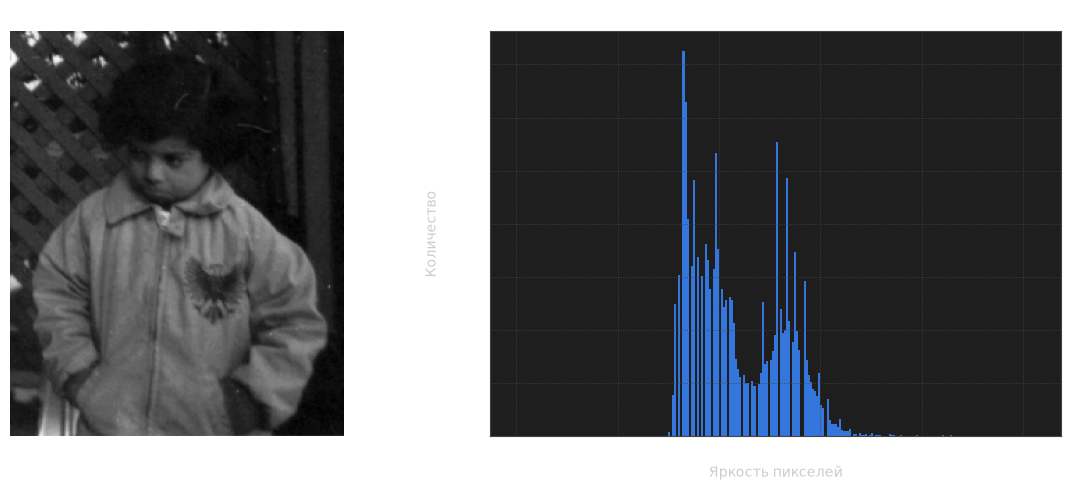

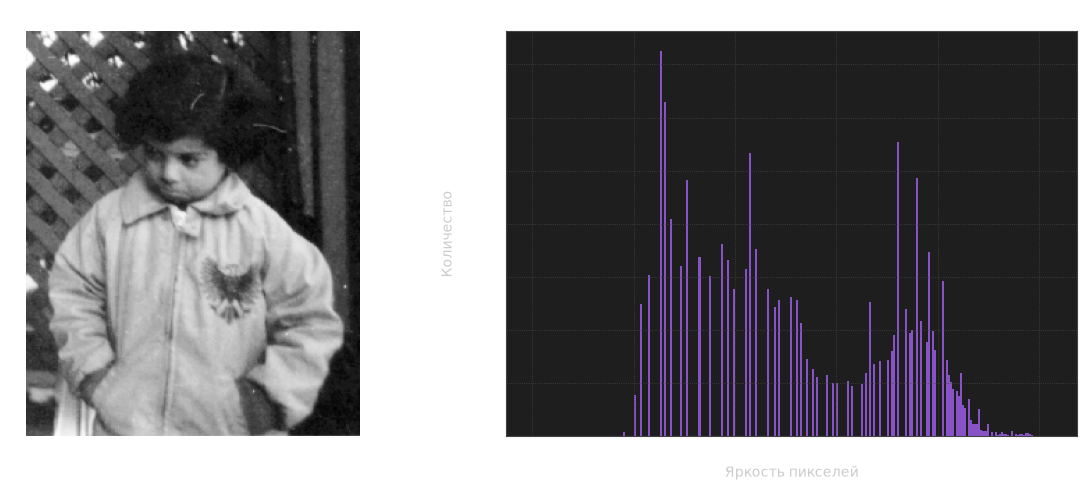

In [109]:
plot_image_and_hist(
    img,
    title_prefix="Исходное",
    hist_color="#3a86ff"
)

plot_image_and_hist(
    img_contrast, 
    title_prefix="Растяжение контрастности", 
    hist_color="#9b5de5"
)

#### Изображение аэроснимков через туман

In [150]:
img = load_and_inspect_image(
    "data/cloudes.png", 
    var_name="img"
)

img_contrast = contrast_stretching_sigmoid(
    img, 
    m=0.90,
    E=8
)

 Property      Value                   
───────────────────────────────────────
 Variable      img                     
 Resolution    512 × 512 px            
 Memory Size   256.0 KB (262144 bytes) 
 Data Class    uint8                   

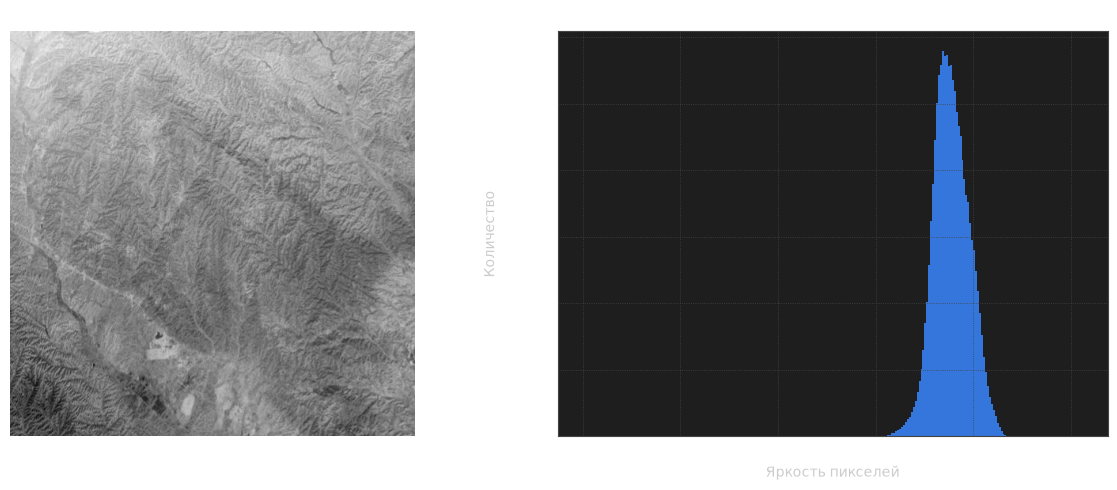

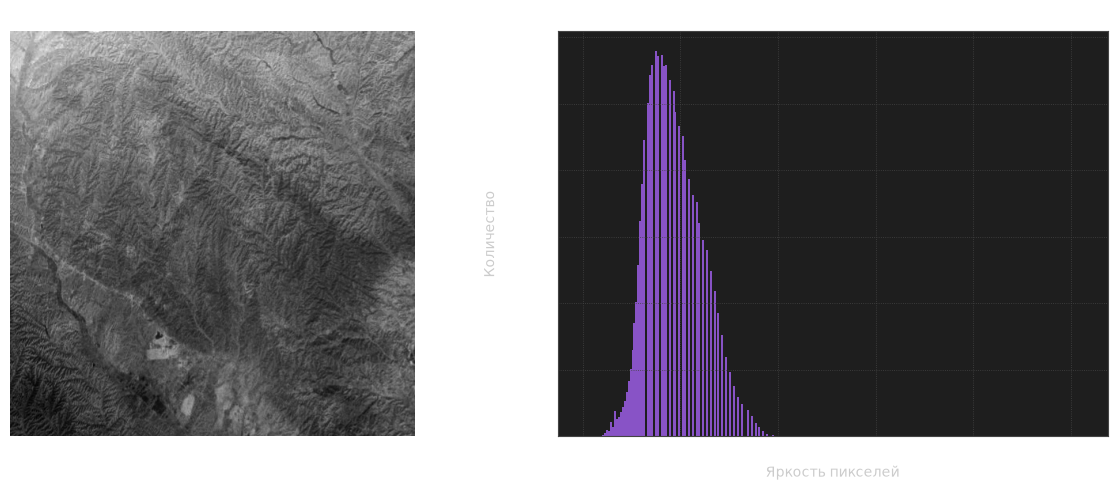

In [151]:
plot_image_and_hist(
    img,
    title_prefix="Исходное",
    hist_color="#3a86ff"
)

plot_image_and_hist(
    img_contrast, 
    title_prefix="Растяжение контрастности", 
    hist_color="#9b5de5"
)